In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
import os
import matplotlib.pyplot as plt
import seaborn as sns

# Add the 'src' directory to the system path
src_dir = os.path.abspath(os.path.join(os.getcwd(), "..", "src"))
sys.path.insert(0, src_dir)

# Now you can import the module
import standardised_pipeline_utils
from sklearn.preprocessing import MinMaxScaler
from joblib import dump, load
from scipy.stats import pearsonr

# Pearson


In [44]:
pearson = load('data/full_pearson.joblib')
pearson


,A1BG,A1BG-AS1,A1CF,A2M,A2M-AS1,A2ML1,A4GALT,AAAS,AACS,AACSP1,...,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3
proteins,,,,,,,,,,,,,,,,,,,,,
A2M,0.248871,0.218735,0.000000,0.373828,0.102893,0.000000,0.000000,0.000000,0.000000,0.0,...,0.126432,0.000000,0.000000,0.0,0.000000,0.0,0.209332,0.177354,0.000000,0.000000
AAAS,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.157414,0.0,...,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.126199,-0.135638,0.127691
AACS,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.110278,0.000000,0.475468,0.0,...,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000
AAGAB,0.107307,0.000000,0.000000,0.000000,0.000000,-0.137312,-0.122281,0.165741,0.000000,0.0,...,0.186194,0.000000,0.000000,0.0,0.000000,0.0,0.000000,-0.112258,0.221993,0.000000
AAK1,0.146338,0.132895,-0.111890,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,...,0.000000,0.140703,0.103788,0.0,0.000000,0.0,0.264591,0.299297,0.000000,0.123601
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZRANB2,0.000000,0.000000,-0.102888,0.000000,0.000000,0.000000,-0.163852,0.188706,0.000000,0.0,...,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.000000,-0.201050,0.000000,0.190270
ZW10,0.000000,0.000000,0.000000,0.000000,0.153179,0.000000,0.000000,0.000000,0.000000,0.0,...,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.126669,0.000000,0.000000
ZWILCH,0.000000,0.000000,0.000000,0.000000,0.000000,-0.164772,-0.116266,0.162279,0.000000,0.0,...,0.220268,0.157534,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.153827,0.106739


### Pearson Correlations full distribution 

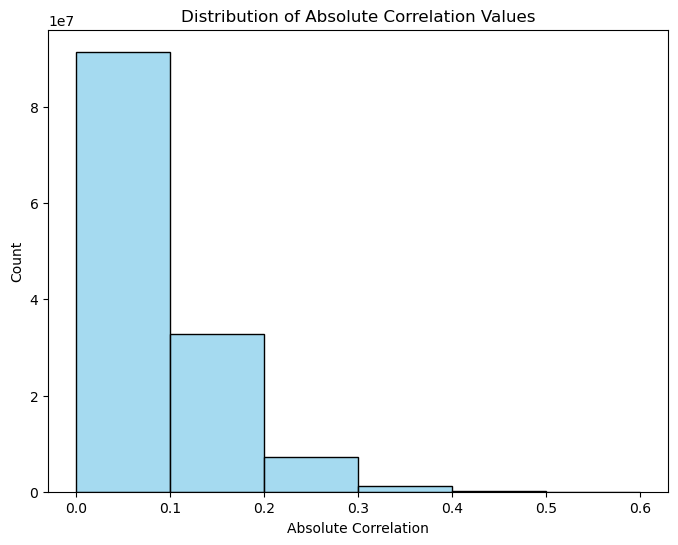

In [26]:
abs_values = pearson.abs().values.flatten()

#bins (0–0.1, 0.1–0.2, 0.2–0.3, ..., 0.9)
bins = np.arange(0, 0.7, 0.1)

plt.figure(figsize=(8, 6))
sns.histplot(abs_values, bins=bins, kde=False, color='skyblue', edgecolor='black')
plt.xlabel('Absolute Correlation')
plt.ylabel('Count')
plt.title('Distribution of Absolute Correlation Values')
plt.xticks(bins)  # Ensure the x-axis shows the bin edges
plt.show()


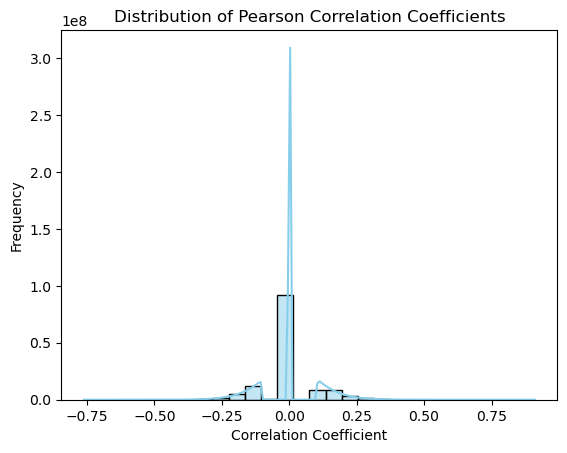

In [ ]:
data = pearson.values.flatten()

# Create a histogram with a kernel density estimate (KDE) in skyblue
sns.histplot(data, color='skyblue', kde=True)

# Optional customizations
plt.title("Distribution of Pearson Correlation Coefficients")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Frequency")

# Display the plot
plt.show()

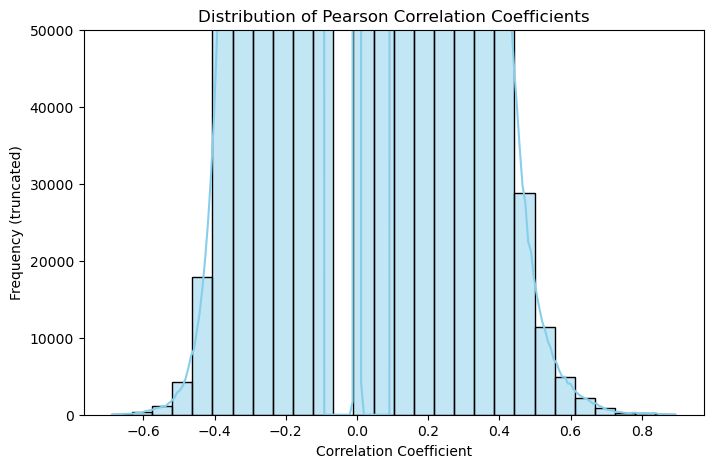

In [49]:
plt.figure(figsize=(8, 5))
sns.histplot(data, color='skyblue', kde=True)
plt.ylim(top=50000)  # Adjust for zeros
plt.title("Distribution of Pearson Correlation Coefficients")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Frequency (truncated)")
plt.show()

another approach, filter out zeros

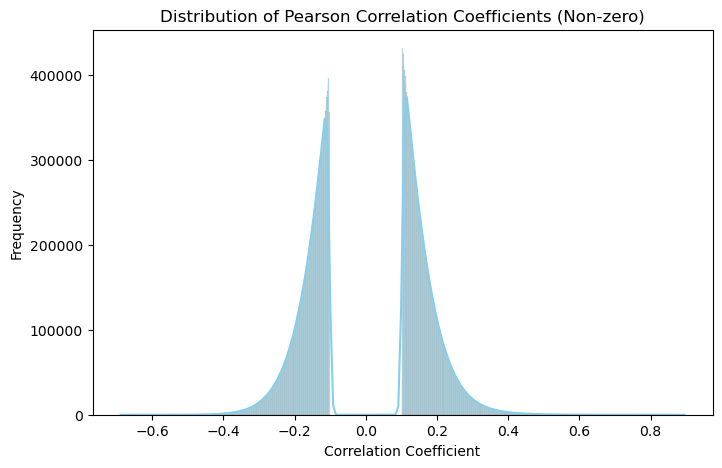

In [48]:
# Filter out exact zeros or near-zeros
non_zero_data = data[np.isclose(data, 0, atol=1e-10) == False]

plt.figure(figsize=(8, 5))
sns.histplot(non_zero_data, color='skyblue', kde=True)
plt.title("Distribution of Pearson Correlation Coefficients (Non-zero)")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Frequency")
plt.show()


### Plot protein - # correlated genes

how many zeros


In [27]:
zero_counts = (pearson == 0).sum(axis=1)

# Compute the number of genes correlated above thresholds
thresholds = [0.1, 0.2, 0.3]
thresh_counts = {t: (pearson.abs() > t).sum(axis=1) for t in thresholds}

In [28]:
# Create summary statistics
def print_summary():
    summary = pd.DataFrame({"Zero Correlations": zero_counts})
    for t in thresholds:
        summary[f"Correlated > {t}"] = thresh_counts[t]
    print(summary)

In [29]:
print_summary()

          Zero Correlations  Correlated > 0.1  Correlated > 0.2  \
proteins                                                          
A2M                   16621              9374              2238   
AAAS                  21095              4900               335   
AACS                  21674              4321               170   
AAGAB                 18766              7229               692   
AAK1                  16124              9871              2548   
...                     ...               ...               ...   
ZRANB2                18648              7347               811   
ZW10                  23115              2880                97   
ZWILCH                18555              7440               705   
ZYX                   17453              8542              1593   
ZZZ3                  18930              7065               701   

          Correlated > 0.3  
proteins                    
A2M                    270  
AAAS                     6  
AACS        

The following histogram displays how many genes per protein have correlations above 0.1 (absolute value). It helps to understand whether most genes have weak or strong correlations with each protein.

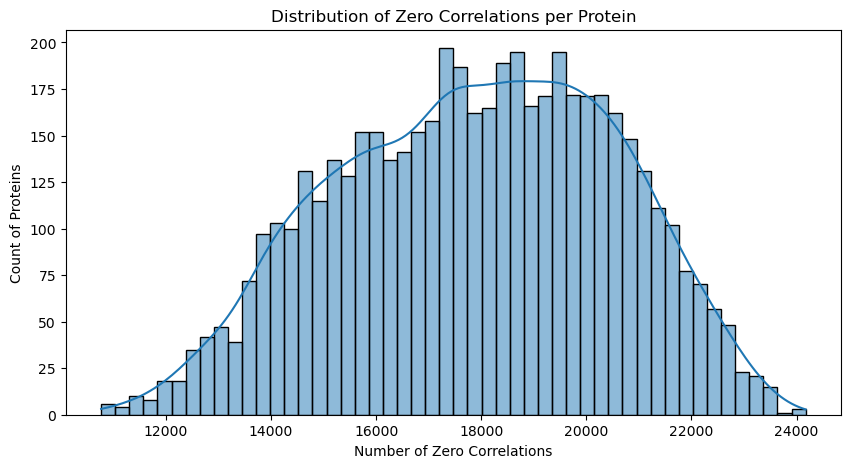

In [30]:
# Cell 1: Plot histogram of zero counts
plt.figure(figsize=(10, 5))
sns.histplot(zero_counts, bins=50, kde=True)
plt.xlabel("Number of Zero Correlations")
plt.ylabel("Count of Proteins")
plt.title("Distribution of Zero Correlations per Protein")
plt.show()

## Above 0.1 absolute correlation

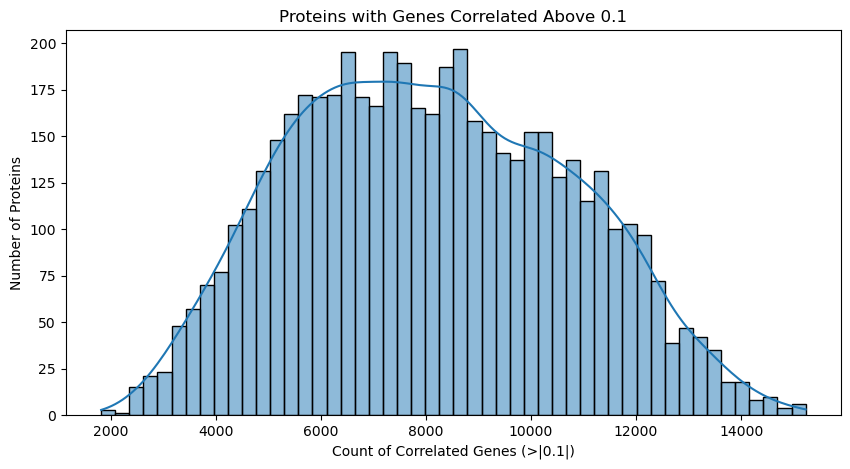

In [31]:
plt.figure(figsize=(10, 5))
sns.histplot(thresh_counts[0.1], bins=50, kde=True)
plt.xlabel("Count of Correlated Genes (>|0.1|)")
plt.ylabel("Number of Proteins")
plt.title("Proteins with Genes Correlated Above 0.1")
plt.show()

## Above 0.2 absolute correlation

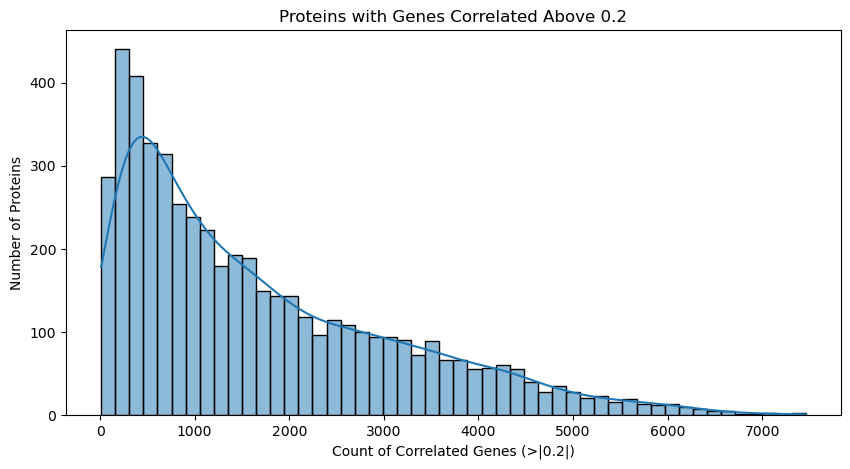

In [32]:
plt.figure(figsize=(10, 5))
sns.histplot(thresh_counts[0.2], bins=50, kde=True)
plt.xlabel("Count of Correlated Genes (>|0.2|)")
plt.ylabel("Number of Proteins")
plt.title("Proteins with Genes Correlated Above 0.2")
plt.show()

## Above 0.3 absolute correlation

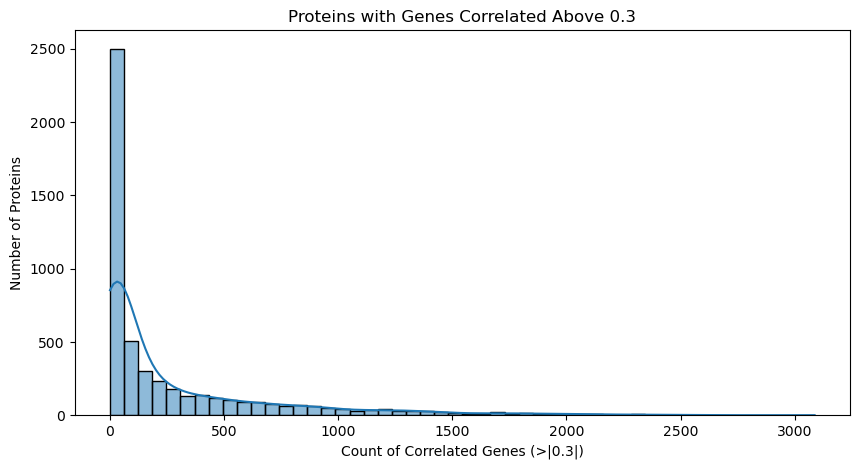

In [33]:
plt.figure(figsize=(10, 5))
sns.histplot(thresh_counts[0.3], bins=50, kde=True)
plt.xlabel("Count of Correlated Genes (>|0.3|)")
plt.ylabel("Number of Proteins")
plt.title("Proteins with Genes Correlated Above 0.3")
plt.show()

# Spearman

In [34]:
spearman = load('data/full_spearman.joblib')
spearman

,A1BG,A1BG-AS1,A1CF,A2M,A2M-AS1,A2ML1,A4GALT,AAAS,AACS,AACSP1,...,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3
proteins,,,,,,,,,,,,,,,,,,,,,
A2M,0.259988,0.233929,-0.116902,0.230195,0.000000,-0.142924,0.000000,0.000000,0.000000,0.0,...,0.139395,0.000000,0.000000,0.000000,0.000000,0.000000,0.225174,0.170703,0.000000,0.123180
AAAS,0.000000,0.000000,0.000000,0.000000,0.121819,0.111012,0.000000,0.000000,-0.166863,0.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.109546,0.000000,0.000000,-0.127864,0.114503
AACS,0.000000,0.000000,0.000000,0.000000,0.000000,-0.147828,0.000000,0.000000,0.446383,0.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
AAGAB,0.127329,0.103151,0.000000,0.000000,0.000000,-0.157370,-0.153830,0.197541,0.120025,0.0,...,0.218814,0.000000,0.117859,0.117173,0.000000,0.000000,0.000000,0.000000,0.209716,0.000000
AAK1,0.182794,0.179434,0.000000,0.000000,0.000000,-0.114290,0.000000,0.000000,0.000000,0.0,...,0.000000,0.000000,0.144951,0.000000,0.000000,0.000000,0.239220,0.291094,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
RUVBL2,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.106743,-0.106265,0.0,...,0.000000,0.000000,0.000000,0.000000,0.150135,0.000000,0.000000,0.000000,0.000000,0.000000
RYBP,0.106975,0.000000,0.000000,0.000000,0.000000,0.000000,-0.208265,0.189727,0.000000,0.0,...,0.000000,0.183956,0.000000,0.000000,0.218500,0.000000,0.000000,-0.125549,0.156089,0.000000
S100A10,-0.295469,-0.275389,0.129749,-0.177183,0.000000,0.120204,0.359290,-0.332902,0.000000,0.0,...,0.000000,-0.147222,0.000000,0.000000,-0.194365,0.000000,0.000000,0.235213,-0.181334,0.000000


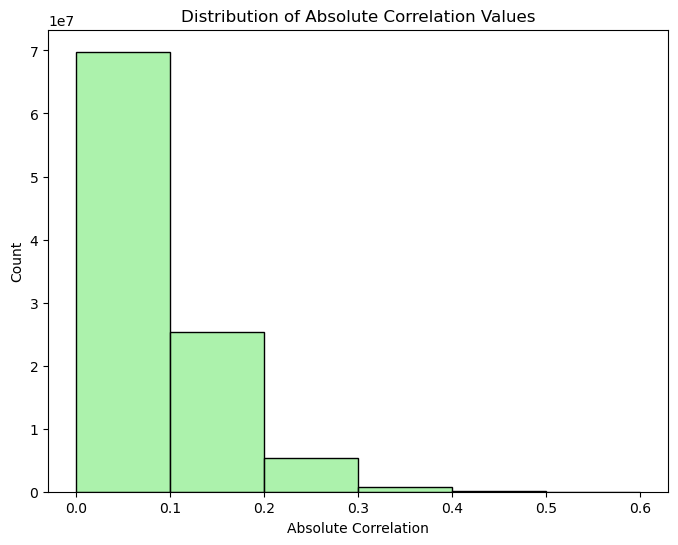

In [35]:
abs_values = spearman.abs().values.flatten()

#bins (0–0.1, 0.1–0.2, 0.2–0.3, ..., 0.9)
bins = np.arange(0, 0.7, 0.1)

plt.figure(figsize=(8, 6))
sns.histplot(abs_values, bins=bins, kde=False, color='lightgreen', edgecolor='black')
plt.xlabel('Absolute Correlation')
plt.ylabel('Count')
plt.title('Distribution of Absolute Correlation Values')
plt.xticks(bins)  # Ensure the x-axis shows the bin edges
plt.show()


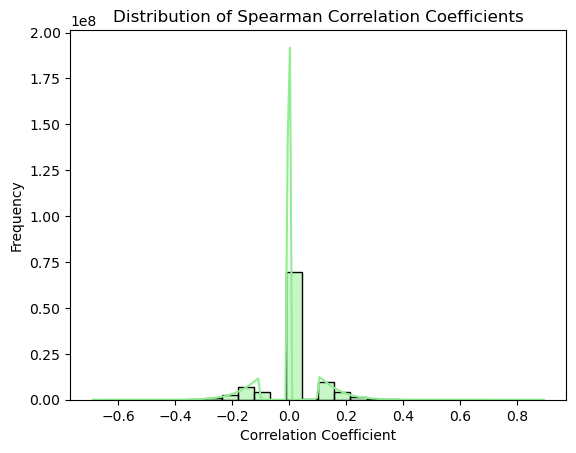

In [50]:
data = spearman.values.flatten()

# Create a histogram with a kernel density estimate (KDE) in skyblue
sns.histplot(data, color='lightgreen', kde=True)

# Optional customizations
plt.title("Distribution of Spearman Correlation Coefficients")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Frequency")

# Display the plot
plt.show()

filter out zeros

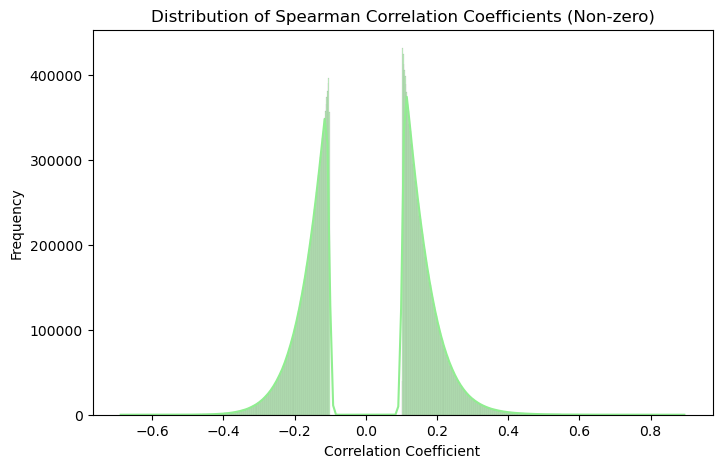

In [52]:
# Filter out exact zeros or near-zeros
non_zero_data = data[np.isclose(data, 0, atol=1e-10) == False]

plt.figure(figsize=(8, 5))
sns.histplot(non_zero_data, color='lightgreen', kde=True)
plt.title("Distribution of Spearman Correlation Coefficients (Non-zero)")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Frequency")
plt.show()

### Plot protein - # correlated genes

how many zeros


In [36]:
zero_counts = (spearman == 0).sum(axis=1)

# Compute the number of genes correlated above thresholds
thresholds = [0.1, 0.2, 0.3]
thresh_counts = {t: (spearman.abs() > t).sum(axis=1) for t in thresholds}

In [37]:
print_summary()

          Zero Correlations  Correlated > 0.1  Correlated > 0.2  \
proteins                                                          
A2M                   15713             10282              2847   
AAAS                  21163              4832               240   
AACS                  22157              3838               121   
AAGAB                 17925              8070               872   
AAK1                  15616             10379              2799   
...                     ...               ...               ...   
RUVBL2                21625              4370               155   
RYBP                  15113             10882              2730   
S100A10               11266             14729              6753   
S100A11               14069             11926              3535   
S100A13               16522              9473              1810   

          Correlated > 0.3  
proteins                    
A2M                    372  
AAAS                     0  
AACS        

The following histogram displays how many genes per protein have correlations above 0.1 (absolute value). It helps to understand whether most genes have weak or strong correlations with each protein.

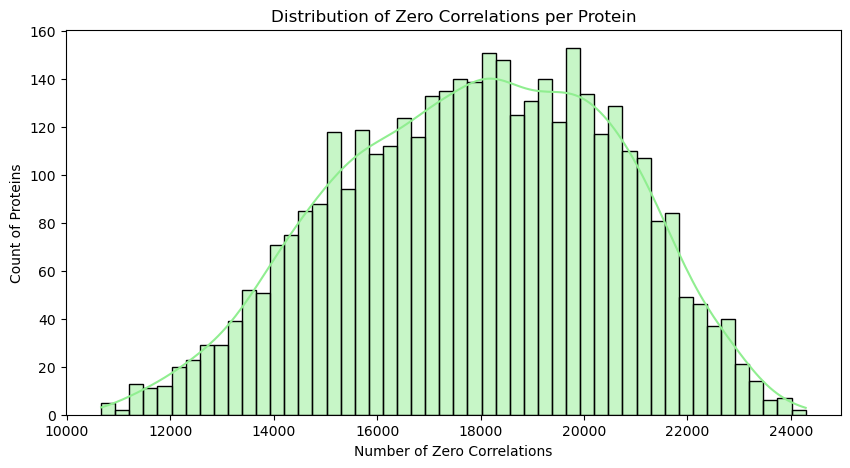

In [38]:
# Cell 1: Plot histogram of zero counts
plt.figure(figsize=(10, 5))
sns.histplot(zero_counts, bins=50, color ="lightgreen", kde=True)
plt.xlabel("Number of Zero Correlations")
plt.ylabel("Count of Proteins")
plt.title("Distribution of Zero Correlations per Protein")
plt.show()

## Above 0.1 absolute correlation

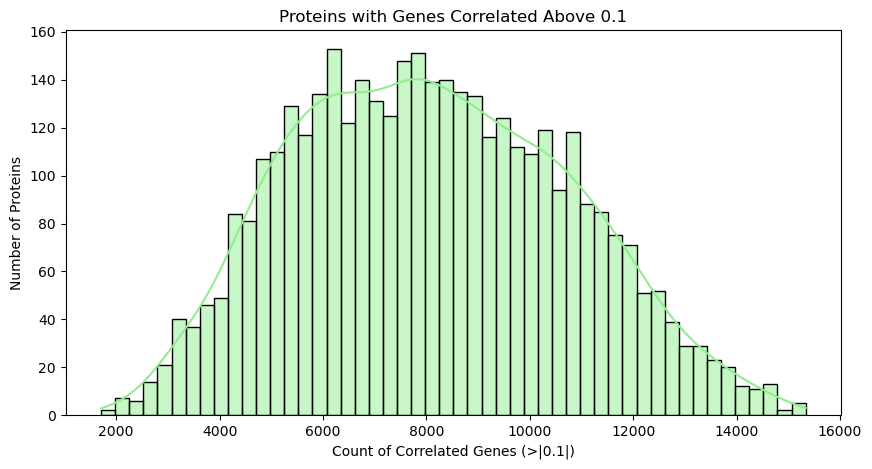

In [39]:
plt.figure(figsize=(10, 5))
sns.histplot(thresh_counts[0.1], bins=50, color ="lightgreen", kde=True)
plt.xlabel("Count of Correlated Genes (>|0.1|)")
plt.ylabel("Number of Proteins")
plt.title("Proteins with Genes Correlated Above 0.1")
plt.show()

## Above 0.2 absolute correlation

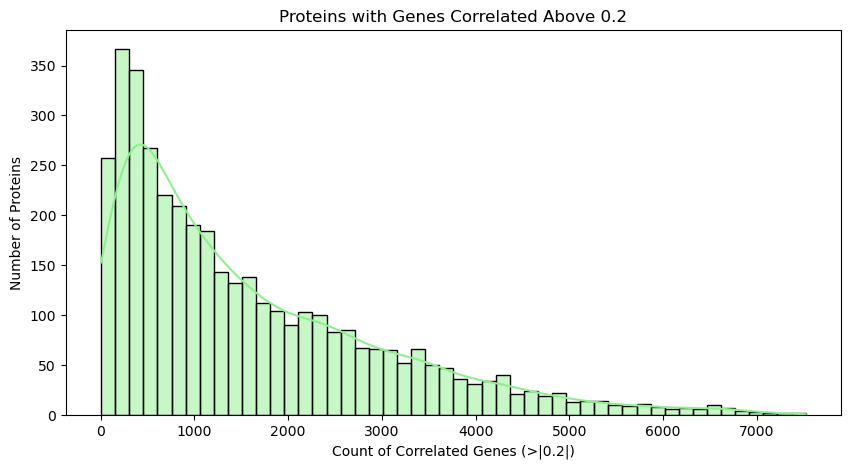

In [40]:
plt.figure(figsize=(10, 5))
sns.histplot(thresh_counts[0.2], bins=50,color ="lightgreen",  kde=True)
plt.xlabel("Count of Correlated Genes (>|0.2|)")
plt.ylabel("Number of Proteins")
plt.title("Proteins with Genes Correlated Above 0.2")
plt.show()

## Above 0.3 absolute correlation

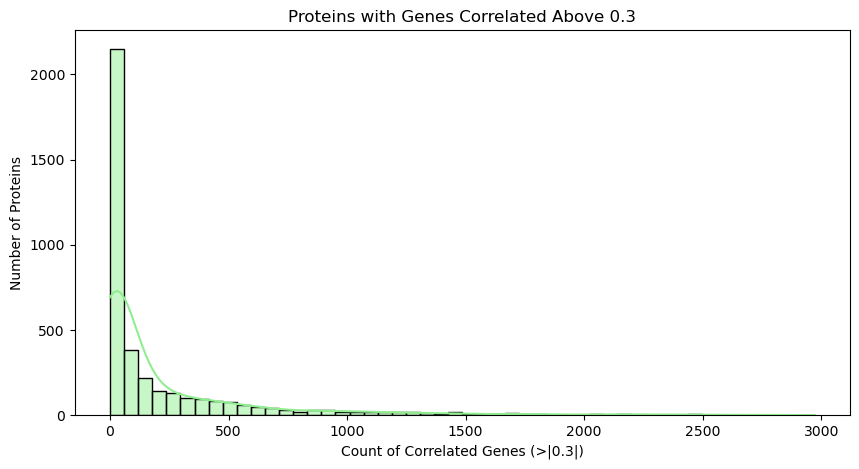

In [41]:
plt.figure(figsize=(10, 5))
sns.histplot(thresh_counts[0.3], bins=50,color ="lightgreen",  kde=True)
plt.xlabel("Count of Correlated Genes (>|0.3|)")
plt.ylabel("Number of Proteins")
plt.title("Proteins with Genes Correlated Above 0.3")
plt.show()